# Optimize open-weight model for SageMaker endpoint using AWS Python API (boto3)

In this notebook, we will show how to optimize the `Qwen/Qwen3.5-4B` model on a SageMaker AI endpoint.

In Lab 1 you chose the deployment settings yourself. Here, SageMaker GenAI Inference Recommender searches the settings for you: it deploys candidate configurations, benchmarks each one with your workload, and returns ranked recommendations you can deploy directly.

The workflow:

- Upload the model weights to Amazon S3
- Define the workload and start a recommendation job
- Review the top recommendation
- Deploy it and send a test request

## Setup

Install boto3 and `huggingface_hub` (used to download the model weights), create the SageMaker AI clients, and look up the execution role. The helpers are the same as in Lab 1.

In [ ]:
%pip install --upgrade --quiet --no-warn-conflicts boto3 huggingface_hub

In [ ]:
import time
import re
import json
import boto3
from IPython.display import display, Markdown, clear_output

boto_session = boto3.Session()
region = boto_session.region_name
account_id = boto3.client("sts").get_caller_identity()["Account"]

sm = boto3.client("sagemaker")  # client to intreract with SageMaker
sm_runtime = boto3.client("sagemaker-runtime")  # client to intreract with SageMaker Endpoints

bucket = f"sagemaker-{region}-{account_id}"

In [ ]:
#
# Helper functions to remove dependency on SageMaker Python SDK
#
def get_sagemaker_role():
    arn = boto3.client("sts").get_caller_identity()["Arn"]
    return re.sub(r"^(.+)sts::(\d+):assumed-role/(.+?)/.*$", r"\1iam::\2:role/\3", arn)


def _wait_for_resource(describe_fn, name_key, status_key, label, name, sleep_time=60):
    """Poll a SageMaker resource until it leaves 'Creating' or "Updating" state."""
    progress = ""
    while True:
        status = describe_fn(**{name_key: name})[status_key]
        if status not in ("Creating", "Updating"):
            break
        progress += "."
        clear_output(wait=True)
        print(f"Waiting for '{name}': {progress}")
        time.sleep(sleep_time)
    print(f"{label}: '{name}', Status: '{status}'")


def wait_for_endpoint(endpoint_name: str, sleep_time: int = 60):
    _wait_for_resource(
        sm.describe_endpoint, "EndpointName", "EndpointStatus",
        "Endpoint", endpoint_name, sleep_time,
    )


def wait_for_ic(ic_name: str, sleep_time: int = 60):
    _wait_for_resource(
        sm.describe_inference_component, "InferenceComponentName", "InferenceComponentStatus",
        "IC", ic_name, sleep_time,
    )

In [ ]:
#
# Overwrite with your role ARN if you are running this notebook outside of SageMaker Studio
#
role = None

if role == None:
    role = get_sagemaker_role()
print(role)

## Recommendation service

Optimizations apply at several layers: the instance type, the number of model copies per instance, serving framework settings such as tensor parallel degree, batch size and context length, and model techniques such as speculative decoding. The slides below show how quickly these choices multiply.

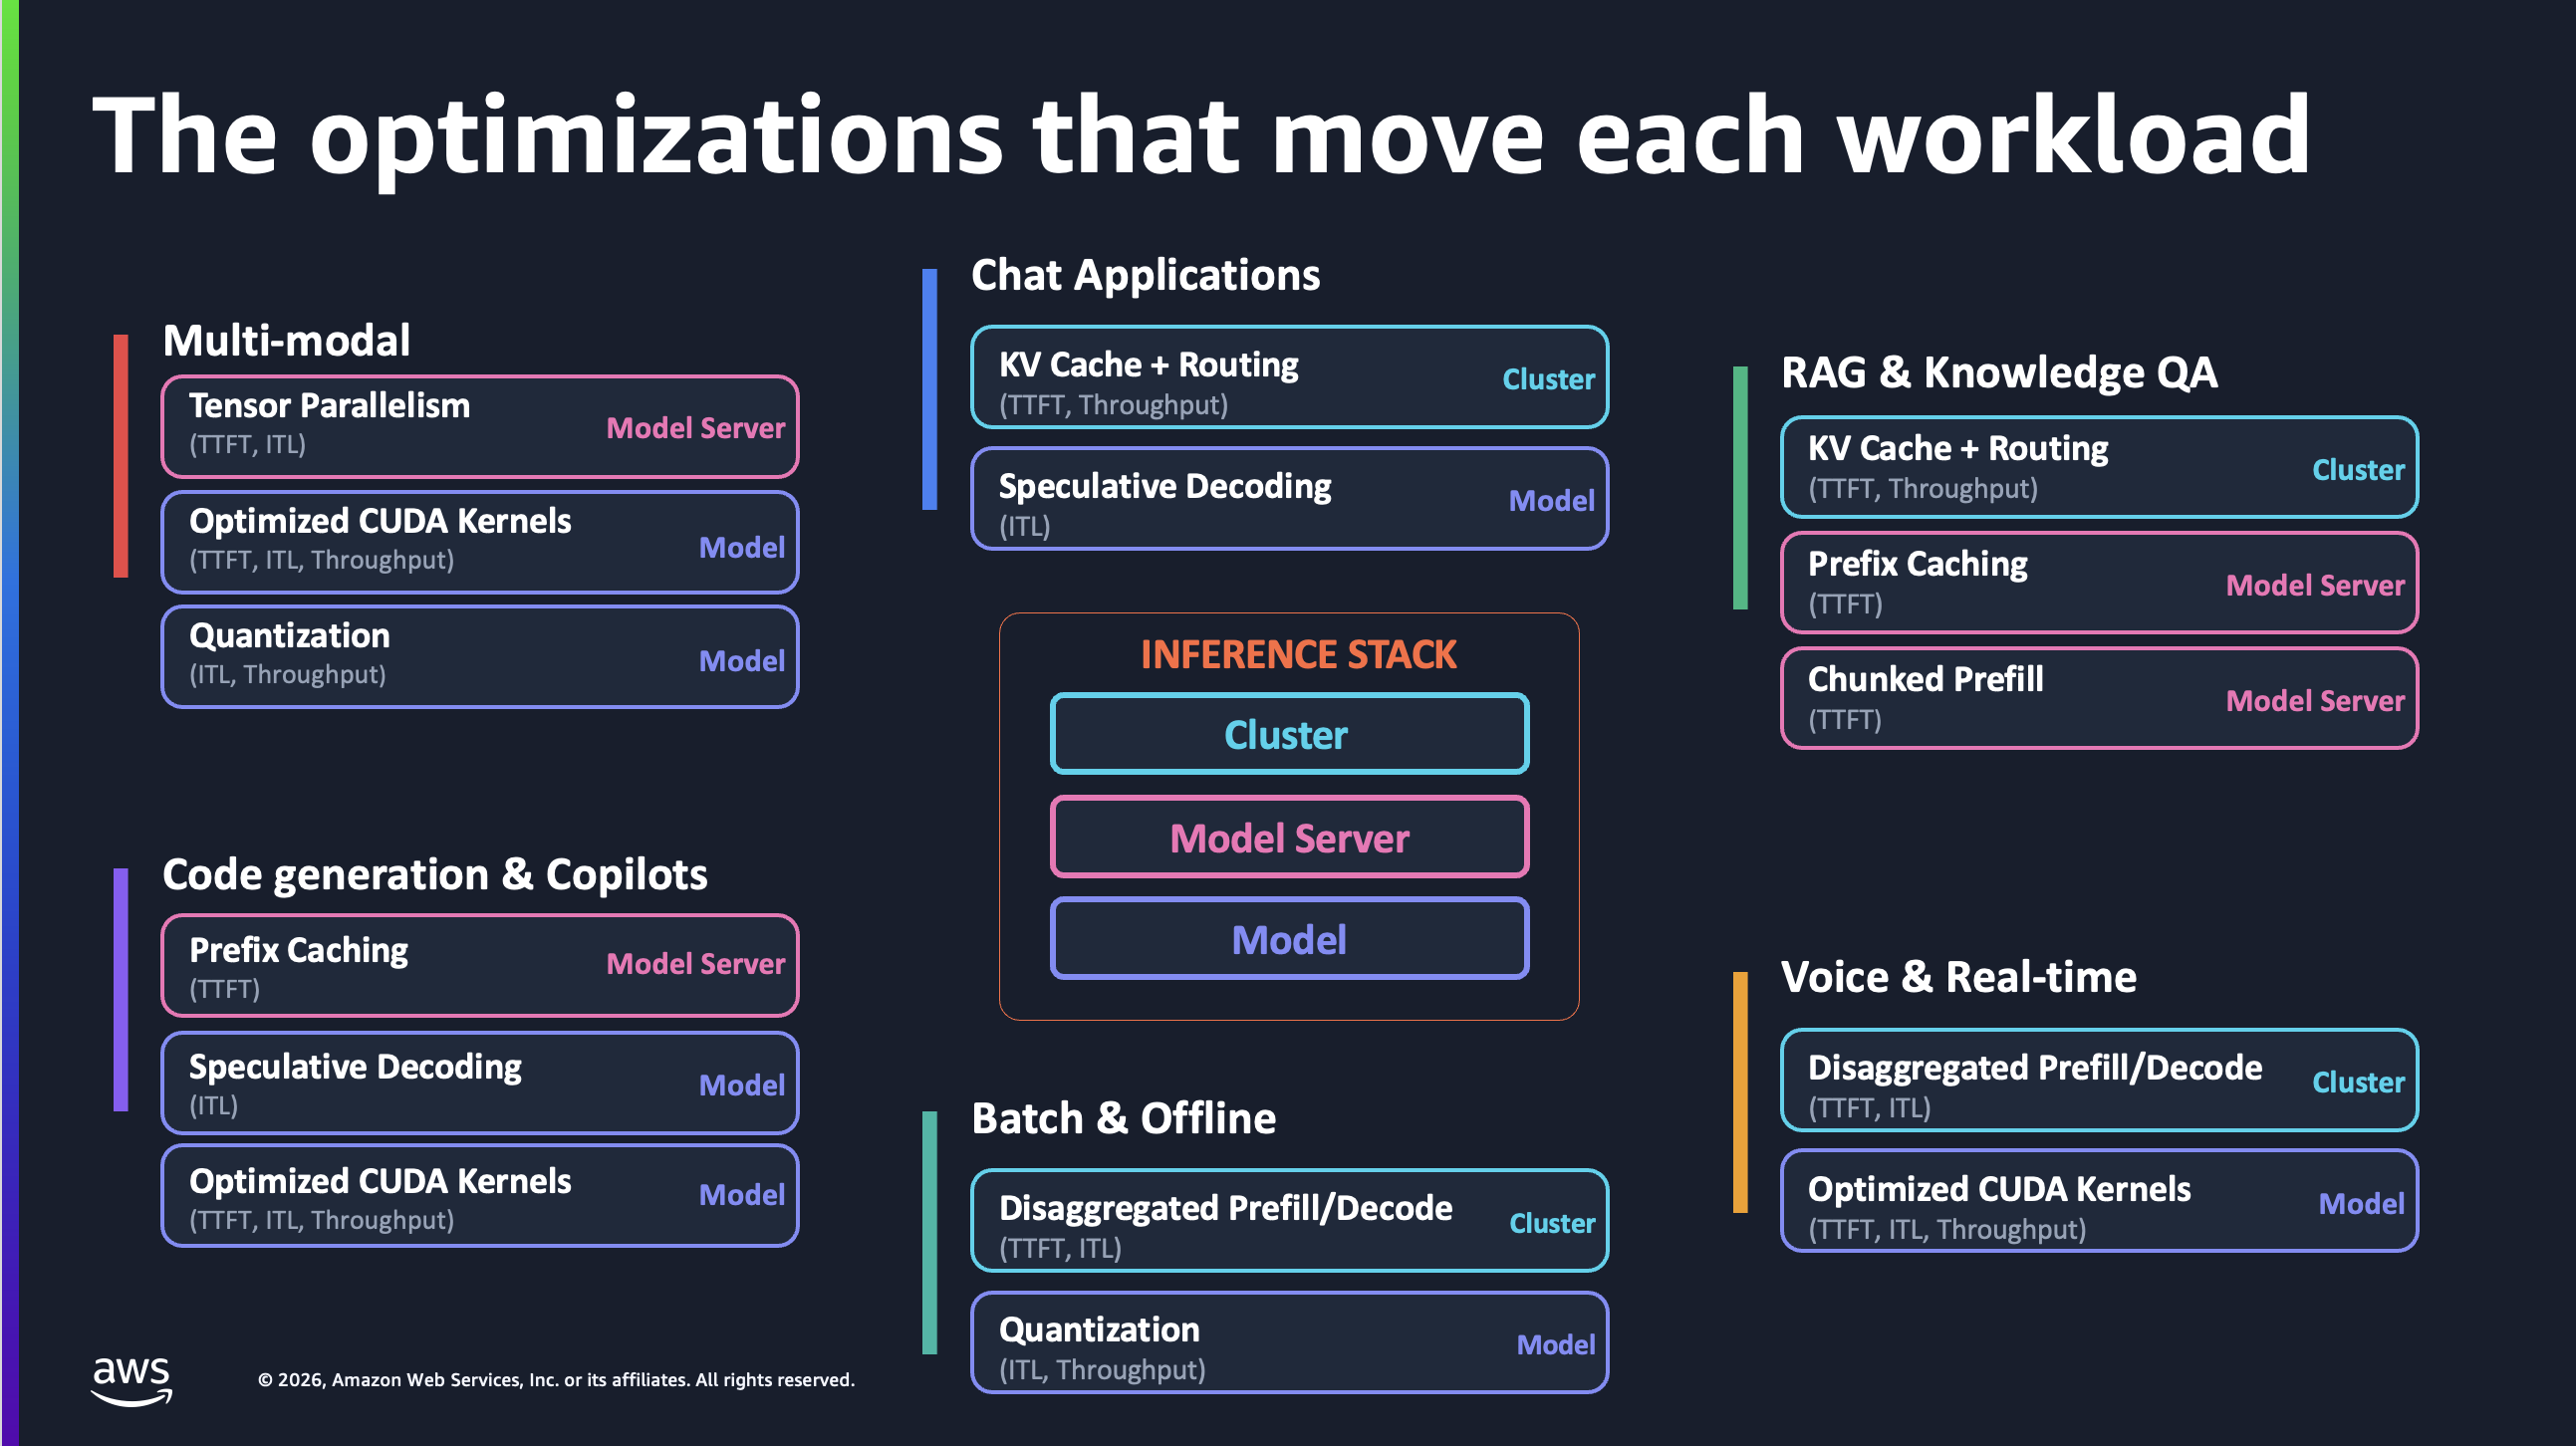

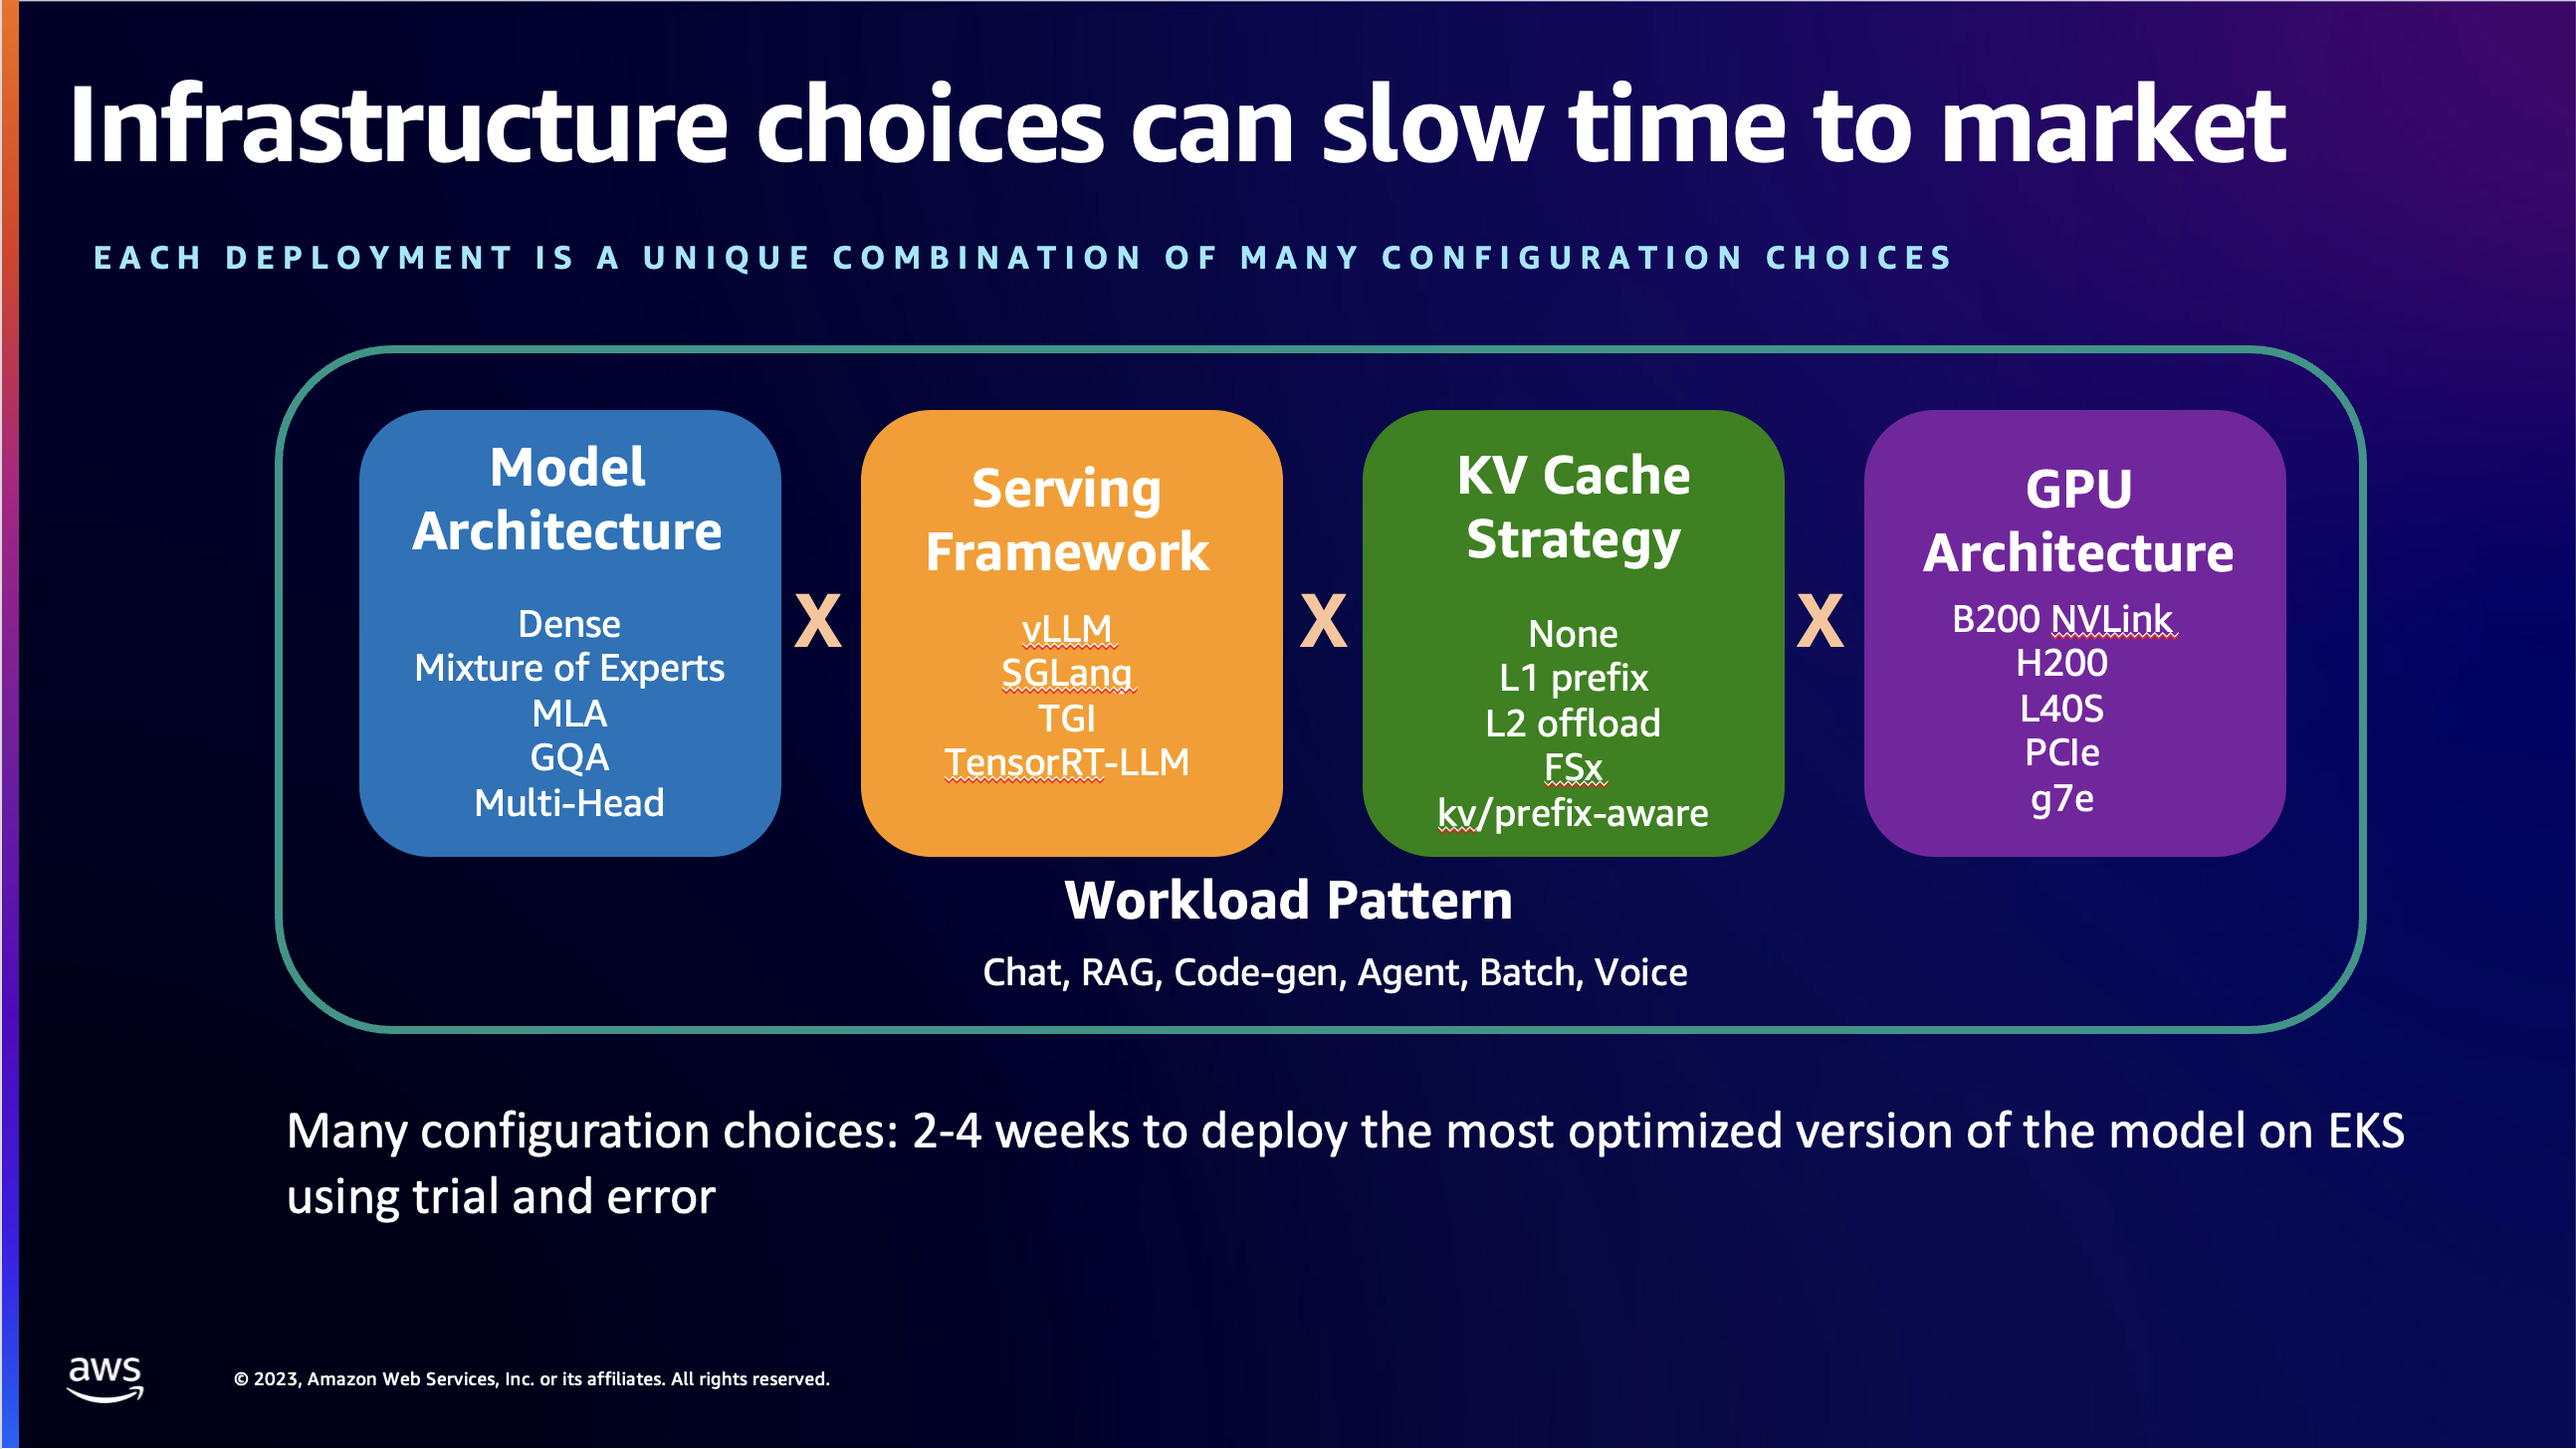

Testing every combination by hand means a deploy-and-benchmark cycle for each one. A recommendation job runs these cycles for you and keeps the best results.

### Download `Qwen/Qwen3.5-4B` to S3

Set the S3 bucket for the model weights and the job output. Replace it with a bucket in your account, for example `sagemaker-<region>-<account-id>`.

In [ ]:
model_id = "Qwen/Qwen3.5-4B"
model_s3_key = f"model/{model_id}"

s3 = boto3.client("s3")

Inference Recommender reads the model weights from Amazon S3. We download the weights from the Hugging Face Hub to the Studio space storage, then upload them to S3. The model is small (about 9 GB), so this takes a few minutes.

In [ ]:
import os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"   # must be set before importing huggingface_hub

from huggingface_hub import snapshot_download
from pathlib import Path

local_model_path = Path("./data")
local_model_path.mkdir(exist_ok=True)

snapshot_download(repo_id=model_id, local_dir=local_model_path)

In [ ]:
import os
# enumerate local files recursively
for root, dirs, files in os.walk(local_model_path):
    for filename in files:
        local_path = os.path.join(root, filename)

        relative_path = os.path.relpath(local_path, local_model_path)
        s3_path = os.path.join(model_s3_key, relative_path)

        print("Uploading %s..." % s3_path)
        s3.upload_file(local_path, bucket, s3_path)

## Recommendation job

This step defines the benchmark workload and registers it with SageMaker as a reusable AI Workload Config.

Define the workload spec

| Parameter | Value | Purpose |
|---|---|---|
| `concurrency` (min/max) | 8 | Holds concurrency at 8 parallel requests (no sweep) |
| `prompt_input_tokens_mean` / `stddev` | 256 / 0 | Every prompt is exactly 256 tokens |
| `output_tokens_mean` / `stddev` | 128 / 0 | Every response is exactly 128 tokens |
| `benchmark_duration` | 60 s | How long measurement runs |
| `warmup_duration` | 10 s | Warm-up period before measurement |
| `streaming` | `True` | Measures streaming metrics (e.g., time to first token) |
| `extra_inputs` | `ignore_eos:true temperature:0` | Makes the model generate the full output length, with deterministic results |
| `random_seed` | 42 | Makes prompt generation reproducible |

Setting both standard deviations to 0 and adding `ignore_eos` gives every request the same token counts. That makes results comparable across runs and configurations.

In [ ]:
# Auto-generate unique names on every run
run_id   = f"{time.strftime('%y%m%d-%H%M%S')}"
cfg_name = f"rec-cfg-{run_id}"
job_name = f"rec-job-{run_id}"

workload_spec = {
    "benchmark": {"type": "aiperf"},
    "parameters": {
        "concurrency": 8,
        "concurrency_min": 8,
        "concurrency_max": 8,
        "prompt_input_tokens_mean": 256,
        "prompt_input_tokens_stddev": 0,
        "output_tokens_mean": 128,
        "output_tokens_stddev": 0,
        "benchmark_duration": 60,
        "streaming": True,
        "warmup_duration": 10,
        "extra_inputs": "ignore_eos:true temperature:0",
        "random_seed": 42,
    },
}

config_resp = sm.create_ai_workload_config(
    AIWorkloadConfigName=cfg_name,
    AIWorkloadConfigs={"WorkloadSpec": {"Inline": json.dumps(workload_spec)}},
)

print(f"Config created: {config_resp['AIWorkloadConfigArn']}")

### Start the recommendation job

The job takes these inputs:

- `ModelSource`: the S3 location of the weights
- `AIWorkloadConfigIdentifier`: the workload defined above
- `PerformanceTarget`: the metric to optimize. `throughput` favors the most output tokens per second. Other targets, such as time to first token, favor responsiveness.
- `ComputeSpec`: the instance types to consider. Here we use one, `ml.g5.12xlarge`, so the job only searches settings on that instance.
- `InferenceSpecification`: the serving framework, vLLM
- `OptimizeModel=False`: use the model as is, without model-level optimizations such as quantization

In [ ]:
model_s3_uri = f"s3://{bucket}/{model_s3_key}/"
job_output = f"s3://{bucket}/recommendations/"

job_resp = sm.create_ai_recommendation_job(
    AIRecommendationJobName=job_name,
    ModelSource={
        "S3": {
            "S3Uri": model_s3_uri,
        }
    },
    OutputConfig={"S3OutputLocation": job_output},
    AIWorkloadConfigIdentifier=cfg_name,
    RoleArn=role,
    PerformanceTarget={
        "Constraints": [
            {"Metric": "throughput"}, # ttft, throuput and cost
        ]
    },
    OptimizeModel=False,
    ComputeSpec={
        "InstanceTypes": ["ml.g7.12xlarge"]
    },
    InferenceSpecification = {"Framework": "VLLM"},
)
print(f"Job created: {job_resp['AIRecommendationJobArn']}")

The job deploys and benchmarks several configurations one after another, so it takes about 15-20 minutes. The cell polls every minute until the job finishes. While it runs, read ahead to see how the recommendation will be deployed.

In [ ]:
while True:
    desc = sm.describe_ai_recommendation_job(AIRecommendationJobName=job_name)
    status = desc["AIRecommendationJobStatus"]
    print(f"  Status: {status}")
    if status in ("Completed", "Failed", "Stopped"):
        break
    time.sleep(60)

### Review the top recommendation

Recommendations are ranked, so we take the first one. It includes:

- **Deployment configuration**: the container image, instance type and count, copies per instance, and the vLLM environment variables to use
- **Optimizations applied**: model-level optimizations, if any (none here, because `OptimizeModel=False`)
- **Expected performance**: throughput, request latency, time to first token and inter-token latency measured during the job

Look at `SM_VLLM_TENSOR_PARALLEL_SIZE` and the copies per instance. A small model often runs best as several single-GPU copies rather than one copy split across all GPUs.

The recommendation points `SM_VLLM_MODEL` to an additional model data path. We attach the weights as the model's primary data source instead, so we reset `SM_VLLM_MODEL` to `/opt/ml/model`, where SageMaker AI places them.

In [ ]:
desc = sm.describe_ai_recommendation_job(AIRecommendationJobName=job_name)

assert desc["AIRecommendationJobStatus"] == "Completed", \
    f"Job is not completed yet. Status: {desc['AIRecommendationJobStatus']}"

# Take the top recommendation
rec = desc["Recommendations"][0]

model_package_arn          = rec["ModelDetails"]["ModelPackageArn"]
inference_spec_name        = rec["ModelDetails"]["InferenceSpecificationName"]
dc                         = rec["DeploymentConfiguration"]
image                      = dc["ImageUri"]
instance_type              = dc["InstanceType"]
instance_count             = dc.get("InstanceCount", 1)
copy_count                 = dc.get("CopyCountPerInstance", 1)
env_vars                   = dc.get("EnvironmentVariables", {})
model_data                 = dc.get("S3")[0]["Uri"]

env_vars["SM_VLLM_MODEL"] = "/opt/ml/model"

print(f"Model Package ARN          : {model_package_arn}")
print(f"Image                      : {image}")
print(f"Inference Specification    : {inference_spec_name}")
print(f"Instance type              : {instance_type}")
print(f"Instance count             : {instance_count}")
print(f"Copies per instance        : {copy_count}")
print(f"Env                        : {env_vars}")
print(f"Model Data                 : {model_data}")

print("\nOptimizations applied:")
for opt in rec.get("OptimizationDetails", []):
    print(f"  - {opt['OptimizationType']}")
print("\nExpected performance:")
for perf in rec.get("ExpectedPerformance", []):
    stat = f" ({perf.get('Stat', '')})"
    print(f"  {perf['Metric']}{stat}: {perf['Value']} {perf.get('Unit', '')}")

## Deploy the model with recommended configuration

We are using the same steps `create_model` -> `create_endpoint_config` -> `create_endpoint` -> `create_inference_component` as in lab1

The only differences from Lab 1 are that the image, environment and instance type come from the recommendation, and the weights load from S3 instead of the Hugging Face Hub.

In [ ]:
model_name = f"model-{time.strftime('%y%m%d-%H%M%S')}"
endpoint_name = model_name
endpoint_config_name = model_name
timeout = 600
variant_name = "v1"

inference_image = image
env = env_vars

In [ ]:
model_data_source = {
    'S3DataSource': {
        'S3Uri': model_data,
        'S3DataType': 'S3Prefix',
        'CompressionType': 'None',
    }
}

_ = sm.create_model(
    ModelName=model_name,
    ExecutionRoleArn=role,
    PrimaryContainer={
        "Image": inference_image,
        "Environment": env,
        'ModelDataSource': model_data_source
    },
)

Create the endpoint configuration and endpoint on the recommended instance type. The cell waits until the endpoint is `InService`.

In [ ]:
_ = sm.create_endpoint_config(
    EndpointConfigName=endpoint_config_name,
    ExecutionRoleArn=role,
    ProductionVariants=[
        {
            "VariantName": variant_name,
            "InstanceType": instance_type,
            "InitialInstanceCount": 1,
            "ContainerStartupHealthCheckTimeoutInSeconds": timeout,
            "InferenceAmiVersion": "al2023-ami-sagemaker-inference-gpu-4-1",
        },
    ],
)

_ = sm.create_endpoint(EndpointName=endpoint_name,
                       EndpointConfigName=endpoint_config_name)

_ = wait_for_endpoint(endpoint_name)

Create the inference component with the recommended number of copies. The instance has two GPUs, so each copy gets `2 // copy_count` GPUs. For example, with four copies each copy runs on one GPU, and SageMaker AI load-balances requests across them.

In [ ]:
ic_name = f"ic-{model_name}"

min_memory_required_in_mb = 1024
number_of_accelerators = 2 // copy_count

_ = sm.create_inference_component(
    InferenceComponentName=ic_name,
    EndpointName=endpoint_name,
    VariantName=variant_name,
    Specification={
        "ModelName": model_name,
        "StartupParameters": {
            "ModelDataDownloadTimeoutInSeconds": timeout,
            "ContainerStartupHealthCheckTimeoutInSeconds": timeout,
        },
        "ComputeResourceRequirements": {
            "MinMemoryRequiredInMb": min_memory_required_in_mb,
            "NumberOfAcceleratorDevicesRequired": number_of_accelerators,
        },

    },
    RuntimeConfig={
        "CopyCount": copy_count,
    },
)
_ = wait_for_ic(ic_name)

## Test invocation

Let's confirm the model was deployed successfully and it processes the request

In [ ]:
#
# Helper function
#
def invoke_endpoint(payload, endpoint_name, inference_component, reasoning_tag="reasoning"):
    start_time = time.time()
    res = sm_runtime.invoke_endpoint(EndpointName=endpoint_name,
                                     InferenceComponentName=inference_component,
                                     Body=json.dumps(payload),
                                     ContentType="application/json")
    response = json.loads(res["Body"].read().decode("utf8"))
    end_time = time.time()

    print(f"✅ Response time: {end_time-start_time:.2f}s\n")

    output = ""
    reasoning = response["choices"][0]["message"].get(reasoning_tag, None)
    if reasoning:
        output += f"### Reasoning:\n---\n{reasoning}\n\n"

    content = response["choices"][0]["message"].get("content", None)
    if content:
        output += f"### Content:\n---\n{content}\n\n---"

    display(Markdown(output))

    return response

In [ ]:
payload={
    "messages": [
        {"role": "user", "content": "Who are you?"}
    ],
}
_ = invoke_endpoint(payload, endpoint_name, ic_name)

## Cleanup

Delete the inference component, endpoint, model, recommendation job and workload configuration. The model weights and job output stay in S3. Delete them as well if you don't need them.

In [ ]:
CLEANUP = True

In [ ]:
if CLEANUP:
    _ = sm.delete_inference_component(InferenceComponentName=ic_name)

In [ ]:
if CLEANUP:
    _ = sm.delete_endpoint(EndpointName=endpoint_name)
    _ = sm.delete_endpoint_config(EndpointConfigName=endpoint_config_name)
    _ = sm.delete_model(ModelName=model_name)

In [ ]:
if CLEANUP:
    _ = sm.delete_ai_recommendation_job(AIRecommendationJobName=job_name)
    _ = sm.delete_ai_workload_config(AIWorkloadConfigName=cfg_name)